In [1]:
import cv2 as cv
from matplotlib import pyplot as plt
import numpy as np

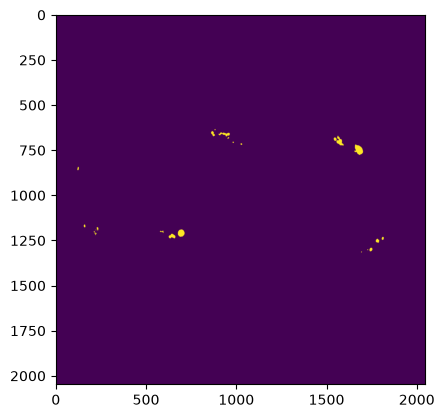

In [15]:
mask = cv.imread("/home/x3nom/Pictures/UPH20220715120930.png", cv.IMREAD_GRAYSCALE)
ret, thresh_mask = cv.threshold(mask, 127, 255, cv.THRESH_BINARY)
plt.imshow(thresh_mask)

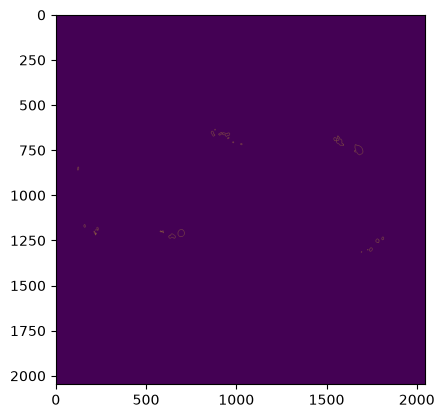

In [16]:
contours, hierarchy = cv.findContours(
    thresh_mask, 
    cv.RETR_EXTERNAL if hasattr(cv, 'cv') else cv.RETR_EXTERNAL, 
    cv.CHAIN_APPROX_SIMPLE
)

# Optional: Draw contours back onto a blank image or the original
contour_output = np.zeros_like(thresh_mask)
cv.drawContours(contour_output, contours, -1, (255), thickness=1) # or thickness=1 for outline

plt.imshow(contour_output)

In [17]:
from shapely.geometry import Polygon


def _DFS(polygons, contours, hierarchy, sibling_id, is_outer, siblings):
  while sibling_id != -1:
    contour = contours[sibling_id].squeeze(axis=1)
    if len(contour) >= 3:
      first_child_id = hierarchy[sibling_id][2]
      children = [] if is_outer else None
      _DFS(
          polygons,
          contours,
          hierarchy,
          first_child_id,
          not is_outer,
          children,
      )

      if is_outer:
        polygon = Polygon(contour, holes=children)
        polygons.append(polygon)
      else:
        siblings.append(contour)

    sibling_id = hierarchy[sibling_id][0]


def generate_polygons(contours, hierarchy):
  hierarchy = hierarchy[0]
  polygons = []
  _DFS(polygons, contours, hierarchy, 0, True, [])
  return polygons


In [ ]:
polygons = generate_polygons(contours, hierarchy)
print(polygons)


[<POLYGON ((1695 1311, 1694 1312, 1693 1312, 1692 1313, 1692 1316, 1694 1316,...>, <POLYGON ((1729 1299, 1728 1300, 1727 1300, 1726 1301, 1727 1302, 1727 1303,...>, <POLYGON ((1744 1291, 1744 1292, 1743 1293, 1742 1293, 1741 1294, 1741 1295,...>, <POLYGON ((1780 1241, 1776 1245, 1776 1246, 1775 1247, 1774 1247, 1775 1248,...>, <POLYGON ((1812 1230, 1811 1231, 1810 1231, 1808 1233, 1808 1235, 1807 1236,...>, <POLYGON ((642 1213, 641 1214, 640 1214, 638 1216, 638 1218, 637 1219, 637 1...>, <POLYGON ((217 1207, 216 1208, 215 1208, 216 1209, 216 1210, 215 1211, 218 1...>, <POLYGON ((212 1198, 211 1199, 211 1202, 212 1203, 212 1205, 214 1205, 215 1...>, <POLYGON ((581 1196, 581 1197, 580 1198, 579 1197, 579 1198, 577 1200, 577 1...>, <POLYGON ((223 1190, 222 1191, 221 1191, 221 1193, 222 1194, 222 1192, 223 1...>, <POLYGON ((696 1189, 695 1190, 690 1190, 689 1191, 688 1191, 687 1192, 685 1...>, <POLYGON ((230 1176, 226 1180, 227 1181, 227 1183, 228 1184, 228 1185, 230 1...>, <POLYGON ((158 

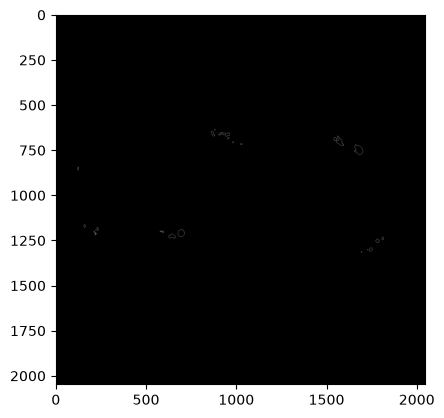

In [20]:
import cv2
import numpy as np


def draw_shapely_polygons(polygons, canvas_shape):
  # Create a blank image or copy your original image
  canvas = np.zeros(canvas_shape, dtype=np.uint8)

  for poly in polygons:
    # 1. Draw the exterior shell
    # Format the coordinates into OpenCV's expected integer shape: (N, 1, 2)
    ext_coords = np.array(poly.exterior.coords, dtype=np.int32).reshape(
        (-1, 1, 2)
    )
    cv2.drawContours(
        canvas, [ext_coords], -1, (255, 255, 255), thickness=1 # cv2.FILLED
    )

    # 2. Cut out the holes by drawing them in the background color (0 / black)
    for interior in poly.interiors:
      int_coords = np.array(interior.coords, dtype=np.int32).reshape((-1, 1, 2))
      cv2.drawContours(
          canvas, [int_coords], -1, (0, 0, 0), thickness=1 # cv2.FILLED
      )

  return canvas

img = np.zeros((2048, 2048, 3), np.uint8)
result_img = draw_shapely_polygons(polygons, img.shape)
plt.imshow(result_img)
